
<div dir=ltr align=center>

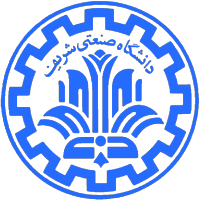

<font color=0F5298 size=7>
Machine Learning <br>
<font color=2565AE size=5>
Computer Engineering Department <br>
Fall 2025 <br>
<font color=3C99D size=5>
    Clustering: K-Means Clustering<br>
<font color=696880 size=4>
    Prepared by Benyamin Ghanbari <br>

<font color=696880 size=2>
    Curated by Alireza Mirshafieian

____

# Student Information

In [ ]:
student_number = '402106701'
full_name = 'Arshia Nazari'

### Image Segmentation Using K-Means Clustering for Color-Based Region Extraction

### Description: 

In this project, you will implement **K-Means clustering from scratch** and use it to perform image segmentation based on color similarity. **Image segmentation** is the process of dividing an image into meaningful regions. In this assignment, segmentation is done using **color clustering**, where every pixel is grouped into one of K color clusters.

**⚠️ Notice:** You are allowed to use **only the imported libraries** and must **follow the provided function structure**.



# 📝 **Project Instructions**

1. **Load the image**  
   Load the input image and convert it into an **RGB numerical array**.

2. **Reshape image to pixels**  
   Flatten the image into a **2D array**, where each row represents one pixel (**R, G, B**).

3. **Initialize K cluster centers**  
   Randomly select **K pixels** to serve as the starting cluster centers.

4. **Assign pixels to nearest cluster**  
   Compute **distances** and assign each pixel to the **closest cluster center**.

5. **Update cluster centers**  
   Recalculate each center as the **mean color** of all pixels assigned to that cluster.

6. **K-Means algorithm**  
   Repeat **assignment** and **update steps** until **convergence** or **max iterations**.

7. **Reconstruct segmented image**  
   Replace each pixel with the **color of its assigned cluster center**.

8. **Using the Elbow Method**  
   Compute the Compute Within-Cluster Sum of Squares **WCSS** for various **K values** to help estimate an **optimal K**.

9. **Run the segmentation**  
   Apply your **full K-Means pipeline** to segment the chosen image.

10. **Display results**  
    Plot and **visualize** the original and segmented images **side-by-side**.


# 📤 **Expected Output**

- A **segmented image** produced by your **K-Means implementation**  
- A **plot showing the Elbow Method curve** (**WCSS vs. K**)  
- **Observe** how changing **K** affects segmentation


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [123]:

# Step 1: Load the image

def load_image(path):
    img = Image.open(path).convert('RGB')
    data = np.array(img)
    return data


# Step 2: Reshape image to pixels

def preprocess_image(image_data):
    original_shape = image_data.shape
    pixels = image_data.reshape(-1 , 3)
    return pixels, original_shape
    



In [124]:

# Step 3: Initialize K cluster centers

def initialize_centers(pixels, k):
    random_idx = np.random.choice(len(pixels), k, replace=False)
    centers = pixels[random_idx]
    return centers


# Step 4: Assign pixels to nearest cluster

def assign_clusters(pixels, centers):
    dist = np.sqrt(np.sum((pixels[:,np.newaxis] - centers)**2, axis=2))
    labels = np.argmin(dist, axis=1)
    return labels


# Step 5: Update cluster centers
    
def update_centers(pixels, labels, k):
    new_centers = []
    for i in range(k):
        cluster_points = pixels[labels == i]
        if len(cluster_points) > 0:
            new_centers.append(cluster_points.mean(axis=0))
        else:
            new_centers.append(pixels[np.random.randint(len(pixels))])


    return np.array(new_centers)



# Step 6: K-Means algorithm

def kmeans(pixels, k, max_iters=10, tol=1e-4):
    centers = initialize_centers(pixels, k)
    for iteration in range(max_iters):
        old_centers = centers.copy()
        labels = assign_clusters(pixels, centers)
        centers = update_centers(pixels, labels, k)
        
        # Check convergence
        if np.all(np.linalg.norm(centers - old_centers, axis=1) < tol):
            print(f"Converged after {iteration + 1} iterations")
            break
    else:
        print(f"Reached max iterations ({max_iters})")


    return centers, labels

In [125]:

# Step 7: Reconstruct segmented image

def recreate_image(labels, centers, image_shape):
    segmented_pixels = centers[labels]
    segmented = (segmented_pixels).astype(np.uint8).reshape(image_shape)
    return segmented

In [126]:
# Step 8: Elbow Method

def calculate_wcss(pixels, max_k=10):
    wcss = []
    for k in range(1, max_k + 1):
        centers, labels = kmeans(pixels, k, max_iters=10)
        distances = np.linalg.norm(pixels - centers[labels], axis=1)
        wcss.append(distances.sum())
        print(f"K={k}, WCSS={wcss[-1]:.2f}")
    return wcss

def plot_elbow(wcss):
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(wcss)+1), wcss, 'bo-')
    plt.title('Elbow Method for Optimal K')
    plt.xlabel('Number of Clusters (K)')
    plt.ylabel('WCSS (Inertia)')
    plt.grid(True, alpha=0.3)
    plt.show()


Converged after 2 iterations
K=1, WCSS=19752828.75
Converged after 7 iterations
K=2, WCSS=8278054.01
Reached max iterations (10)
K=3, WCSS=6128576.95
Reached max iterations (10)
K=4, WCSS=3987286.27
Reached max iterations (10)
K=5, WCSS=3334263.26
Reached max iterations (10)
K=6, WCSS=3091507.33
Reached max iterations (10)
K=7, WCSS=2480994.24
Reached max iterations (10)
K=8, WCSS=2410766.56
Reached max iterations (10)
K=9, WCSS=2105888.91
Reached max iterations (10)
K=10, WCSS=2197437.82


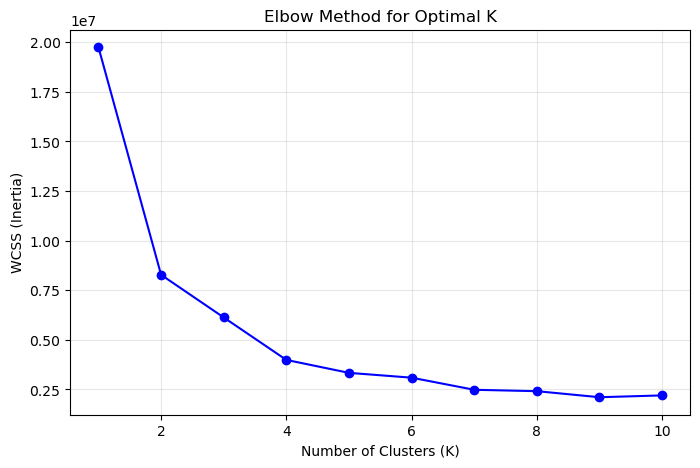

Converged after 16 iterations


In [138]:
# Step 9: Run the segmentation
image_path = 'shrek.jpg'
org_img = load_image(image_path)
pixels, shape = preprocess_image(org_img)
wcss = calculate_wcss(pixels, max_k=10)
plot_elbow(wcss)
k = 4
final_center, final_labels = kmeans(pixels, k, max_iters=30)
segmented_img = recreate_image(final_labels, final_center, shape)


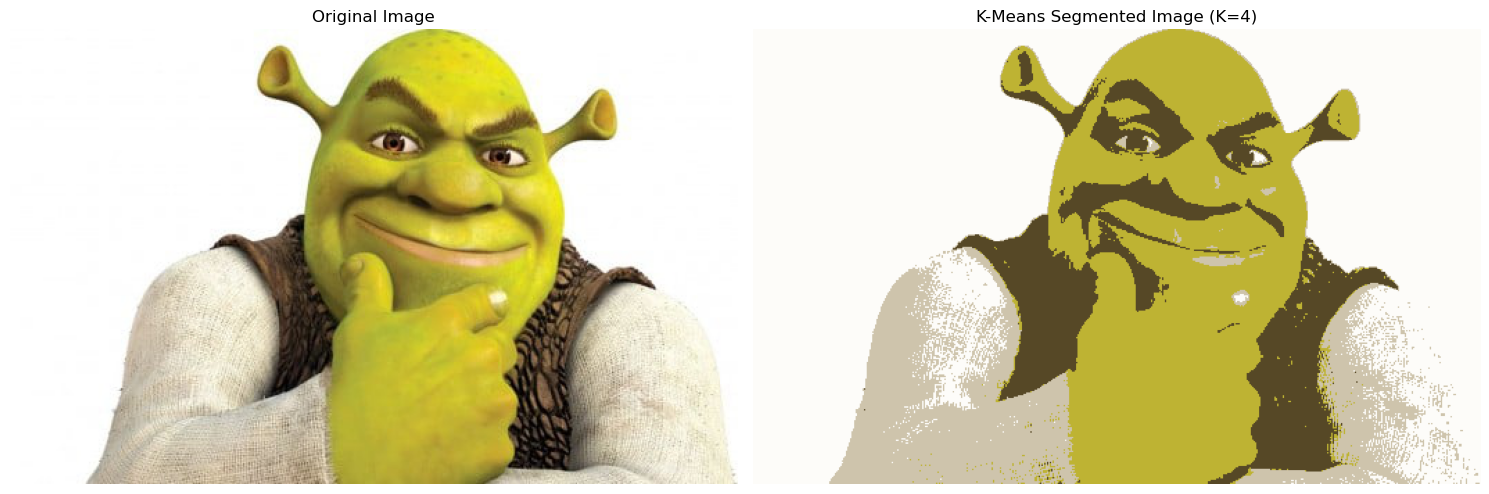

In [139]:
# Step 10: Display results
plt.figure(figsize=(15, 8))

plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(org_img)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title(f"K-Means Segmented Image (K={k})")
plt.imshow(segmented_img)
plt.axis('off')

plt.tight_layout()
plt.show()